In [187]:
import geopandas as gpd
import regionmask
import xarray as xr
import os
import netCDF4
import matplotlib.pyplot as plt
import math
import pandas as pd

In [188]:
os.environ["SHAPE_RESTORE_SHX"] = "YES"

SHAPE_RESTORE_SHX = "YES"
algeria = gpd.read_file("dz.shp")   
ds = xr.open_dataset("data_stream-moda.nc",engine="netcdf4")

mask = regionmask.mask_geopandas(algeria, ds.longitude, ds.latitude)
ds = ds.where(mask.notnull())       
ds = ds.coarsen(latitude=2, longitude=2, boundary="trim").mean()

In [189]:
df = ds.to_dataframe()
df = df.dropna()
df = df.drop(columns=['number','expver'])
df = df.drop_duplicates()
df = df.reset_index()

df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,36.95,3.75,279.760498,284.346924,-5206072.0,7712772.0,-5404634.0,2.046784e+06,3.819242e-04,-0.002082,2.625080,0.556908,100893.875000,0.005114
1,2015-01-01,36.95,3.95,279.408936,283.862549,-4882846.0,7350362.0,-5204614.0,2.267892e+06,4.743487e-04,-0.001953,2.591389,0.508568,99983.875000,0.005336
2,2015-01-01,36.95,4.35,279.160889,283.442627,-5091602.0,7802930.0,-5141586.0,1.903082e+06,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
3,2015-01-01,36.95,6.35,279.016846,282.479736,-4169095.5,7906041.0,-4781862.0,2.699085e+05,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
4,2015-01-01,36.95,6.55,279.324310,282.819580,-4094020.0,7723036.5,-4838696.0,7.665407e+05,2.384782e-04,-0.001637,2.287352,-0.045143,98959.210938,0.004703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764779,2026-09-01,19.15,3.75,282.029541,307.469238,-203487.0,14447492.0,-9939245.0,-4.292967e+06,1.825392e-07,-0.000081,-0.867740,-1.067228,95788.187500,0.000088
764780,2026-09-01,19.15,3.95,282.064209,307.611816,-261701.5,14496558.0,-9942863.0,-4.281062e+06,2.868474e-07,-0.000105,-0.857364,-1.015471,95966.187500,0.000117
764781,2026-09-01,19.15,4.15,281.926025,307.671875,-213609.0,14506127.0,-9969803.0,-4.307196e+06,1.974404e-07,-0.000085,-0.849551,-0.996916,96068.687500,0.000079
764782,2026-09-01,19.15,4.35,281.761963,307.614258,-188365.0,14641952.0,-9969462.0,-4.458993e+06,7.078052e-08,-0.000075,-0.826602,-0.934172,96013.187500,0.000042


In [190]:
#infos
print(df.shape)
print(df.columns.to_list())

(764784, 15)
['valid_time', 'latitude', 'longitude', 'd2m', 't2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']


In [191]:
#some conversions

#slhf,ssr,str,sshf    J/m^2 to W/m^2
for v in ["slhf", "ssr", "str", "sshf"]:
    df[v] = df[v] / 86400

#temperature K to C
df['t2m'] = df['t2m'] - 273.15   
df['d2m'] = df['d2m'] - 273.15 

In [192]:
df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,36.95,3.75,6.610504,11.196930,-60.255463,89.268196,-62.553635,23.689631,3.819242e-04,-0.002082,2.625080,0.556908,100893.875000,0.005114
1,2015-01-01,36.95,3.95,6.258942,10.712555,-56.514420,85.073631,-60.238586,26.248751,4.743487e-04,-0.001953,2.591389,0.508568,99983.875000,0.005336
2,2015-01-01,36.95,4.35,6.010895,10.292633,-58.930580,90.311691,-59.509098,22.026413,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
3,2015-01-01,36.95,6.35,5.866852,9.329742,-48.253422,91.505104,-55.345627,3.123941,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
4,2015-01-01,36.95,6.55,6.174316,9.669586,-47.384491,89.386993,-56.003426,8.871999,2.384782e-04,-0.001637,2.287352,-0.045143,98959.210938,0.004703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764779,2026-09-01,19.15,3.75,8.879547,34.319244,-2.355174,167.216339,-115.037560,-49.687119,1.825392e-07,-0.000081,-0.867740,-1.067228,95788.187500,0.000088
764780,2026-09-01,19.15,3.95,8.914215,34.461823,-3.028953,167.784241,-115.079430,-49.549324,2.868474e-07,-0.000105,-0.857364,-1.015471,95966.187500,0.000117
764781,2026-09-01,19.15,4.15,8.776031,34.521881,-2.472326,167.894989,-115.391235,-49.851807,1.974404e-07,-0.000085,-0.849551,-0.996916,96068.687500,0.000079
764782,2026-09-01,19.15,4.35,8.611969,34.464264,-2.180151,169.467041,-115.387291,-51.608715,7.078052e-08,-0.000075,-0.826602,-0.934172,96013.187500,0.000042


# univariate analysis

In [193]:
def mediane(df):
       df = df.reset_index(drop=True)
       n = len(df)
       return df[n//2] if n % 2 else (df[n//2 - 1] + df[n//2]) / 2

def mode(df):
    mode_df = df.groupby(df.astype(int)).count()
    return mode_df.idxmax()

### 1. 2m dewpoint temperature

In [194]:
df_sorted = df['d2m'].sort_values()


#mean
d2m_mean = df_sorted.mean()

#mediane
d2m_mediane = mediane(df_sorted)


#mode
d2m_mode = mode(df_sorted)

#variance
d2m_variance = df_sorted.var(ddof=0)

#ecart-type
d2m_ecart_type = math.sqrt(d2m_variance)


print(f"mean : {d2m_mean}")
print(f"mediane: {d2m_mediane}")
print(f"mode: {d2m_mode}")
print(f"variance: {d2m_variance}")
print(f"ecart-type: {d2m_ecart_type}")


 

mean : 1.5400587320327759
mediane: 1.321197509765625
mode: 0
variance: 23.30963706970215
ecart-type: 4.828005496030649


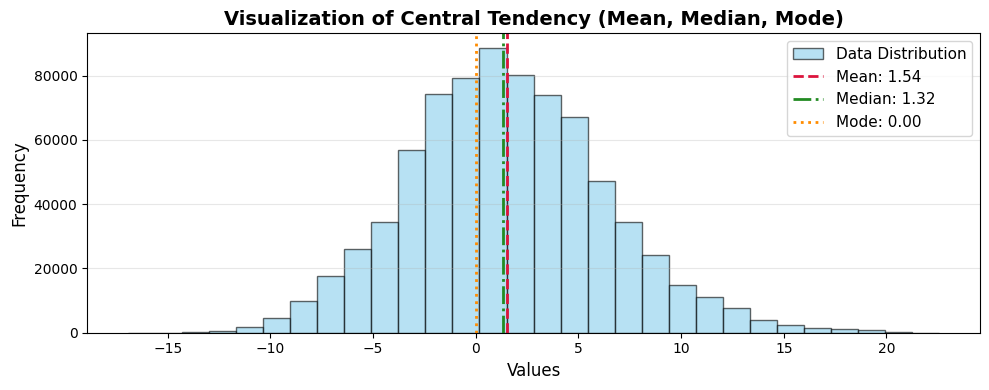

In [195]:
#distribution
plt.figure(figsize=(10, 4))

# Plot the distribution histogram
data = df_sorted
plt.hist(data, bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Data Distribution')

# Draw vertical lines for each central tendency metric
plt.axvline(d2m_mean, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {d2m_mean:.2f}')
plt.axvline(d2m_mediane, color='forestgreen', linestyle='-.', linewidth=2, label=f'Median: {d2m_mediane:.2f}')
plt.axvline(d2m_mode, color='darkorange', linestyle=':', linewidth=2, label=f'Mode: {d2m_mode:.2f}')

# Customize chart elements
plt.title('Visualization of Central Tendency (Mean, Median, Mode)', fontsize=14, fontweight='bold')
plt.xlabel('Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()

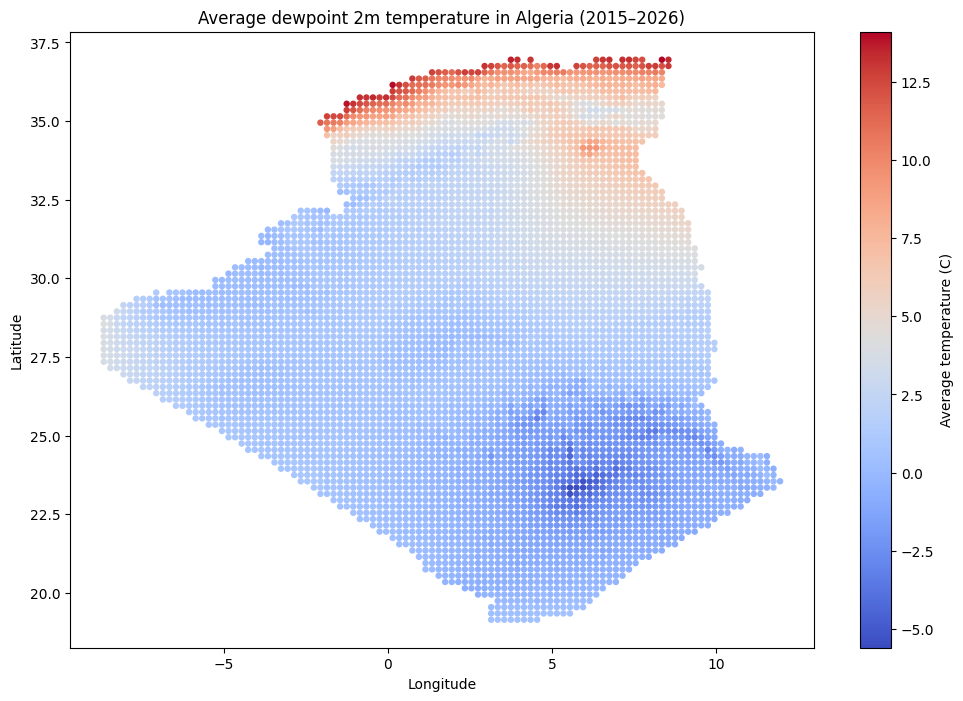

In [196]:


mean_temp = df.groupby(
    ['latitude', 'longitude']
)['d2m'].mean().reset_index()


plt.figure(figsize=(12, 8))

plt.scatter(
    mean_temp['longitude'],
    mean_temp['latitude'],
    c=mean_temp['d2m'],
    cmap='coolwarm',
    s=13
)

plt.colorbar(label='Average temperature (C)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Average dewpoint 2m temperature in Algeria (2015–2026)')
plt.show()

### 2. surface latent heat flux

In [197]:

df_sorted = df['slhf'].sort_values()


#mean
slhf_mean = df_sorted.mean()

#mediane
slhf_mediane = mediane(df_sorted)


#mode
slhf_mode = mode(df_sorted)

#variance
slhf_variance = df_sorted.var(ddof=0)

#ecart-type
slhf_ecart_type = math.sqrt(slhf_variance)


print(f"mean : {slhf_mean}")
print(f"mediane: {slhf_mediane}")
print(f"mode: {slhf_mode}")
print(f"variance: {slhf_variance}")
print(f"ecart-type: {slhf_ecart_type}")


 

mean : -5.762101650238037
mediane: -2.1078009605407715
mode: 0
variance: 129.3625946044922
ecart-type: 11.37376782796678


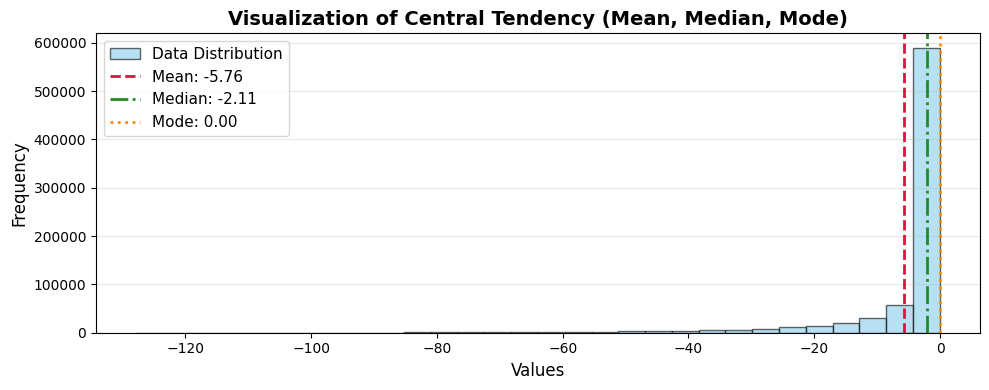

In [198]:
#distribution
plt.figure(figsize=(10, 4))

# Plot the distribution histogram
data = df_sorted
plt.hist(data, bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Data Distribution')

# Draw vertical lines for each central tendency metric
plt.axvline(slhf_mean, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {slhf_mean:.2f}')
plt.axvline(slhf_mediane, color='forestgreen', linestyle='-.', linewidth=2, label=f'Median: {slhf_mediane:.2f}')
plt.axvline(slhf_mode, color='darkorange', linestyle=':', linewidth=2, label=f'Mode: {slhf_mode:.2f}')

# Customize chart elements
plt.title('Visualization of Central Tendency (Mean, Median, Mode)', fontsize=14, fontweight='bold')
plt.xlabel('Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()

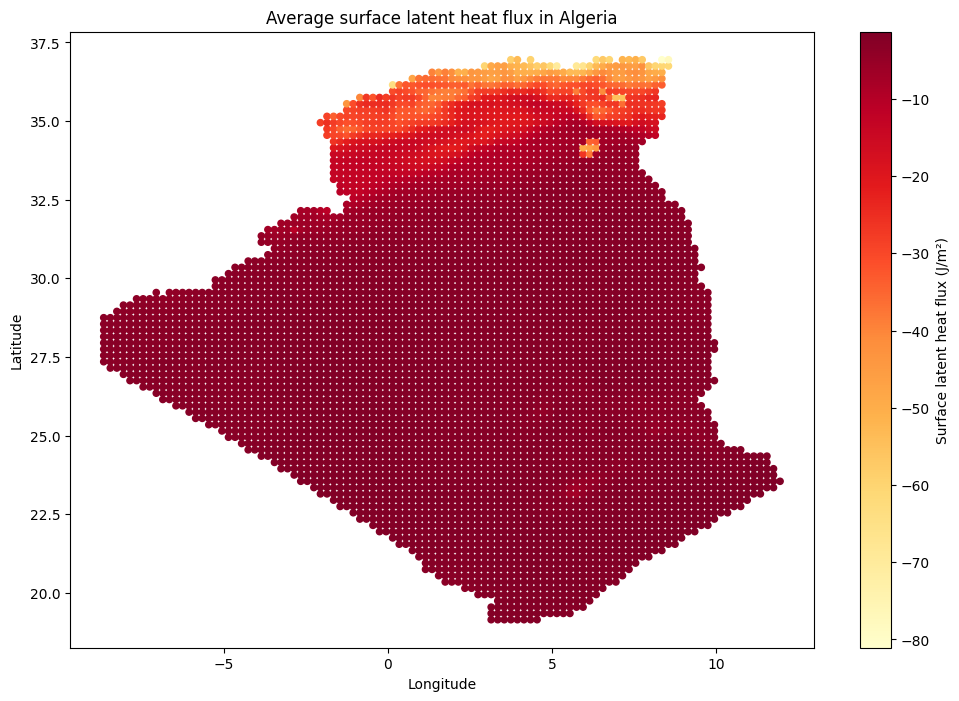

In [199]:
mean_slhf = df.groupby(
    ['latitude', 'longitude']
)['slhf'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 8))

sc = ax.scatter(
    mean_slhf['longitude'],
    mean_slhf['latitude'],
    c=mean_slhf['slhf'],
    cmap='YlOrRd',
    s=20
)

plt.colorbar(sc, ax=ax, label='Surface latent heat flux (J/m²)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Average surface latent heat flux in Algeria')

plt.show()

### 3. surface net solar radiation

In [200]:

df_sorted = df['ssr'].sort_values()


#mean
ssr_mean = df_sorted.mean()

#mediane
ssr_mediane = mediane(df_sorted)


#mode
ssr_mode = mode(df_sorted)

#variance
ssr_variance = df_sorted.var(ddof=0)

#ecart-type
ssr_ecart_type = math.sqrt(ssr_variance)


print(f"mean : {ssr_mean}")
print(f"mediane: {ssr_mediane}")
print(f"mode: {ssr_mode}")
print(f"variance: {ssr_variance}")
print(f"ecart-type: {ssr_ecart_type}")


 

mean : 156.37124633789062
mediane: 161.74330139160156
mode: 188
variance: 2410.452392578125
ecart-type: 49.09635824150428


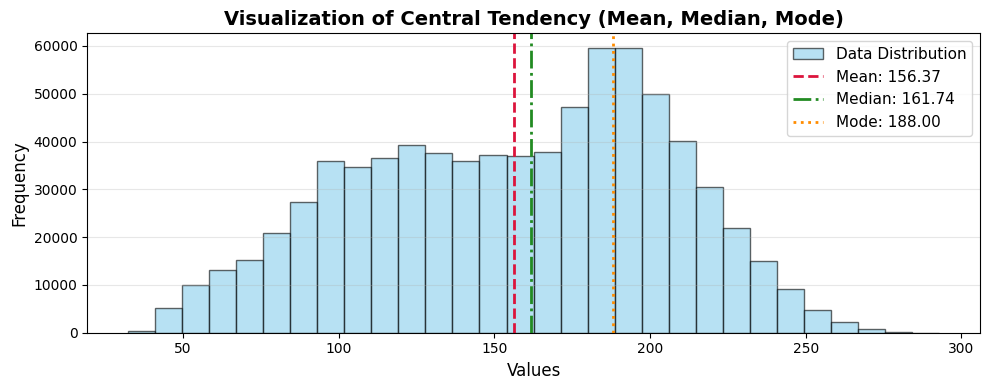

In [201]:
#distribution
plt.figure(figsize=(10, 4))

# Plot the distribution histogram
data = df_sorted
plt.hist(data, bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Data Distribution')

# Draw vertical lines for each central tendency metric
plt.axvline(ssr_mean, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {ssr_mean:.2f}')
plt.axvline(ssr_mediane, color='forestgreen', linestyle='-.', linewidth=2, label=f'Median: {ssr_mediane:.2f}')
plt.axvline(ssr_mode, color='darkorange', linestyle=':', linewidth=2, label=f'Mode: {ssr_mode:.2f}')

# Customize chart elements
plt.title('Visualization of Central Tendency (Mean, Median, Mode)', fontsize=14, fontweight='bold')
plt.xlabel('Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()

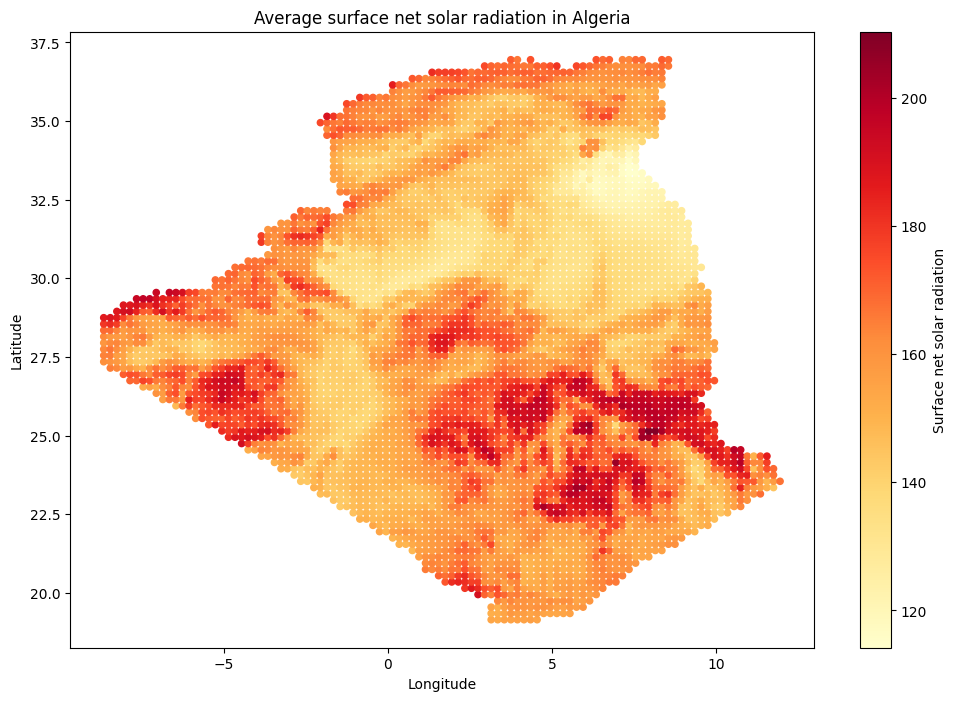

In [202]:
mean_ssr = df.groupby(
    ['latitude', 'longitude']
)['ssr'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 8))

sc = ax.scatter(
    mean_ssr['longitude'],
    mean_ssr['latitude'],
    c=mean_ssr['ssr'],
    cmap='YlOrRd',
    s=20
)

plt.colorbar(sc, ax=ax, label='Surface net solar radiation')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Average surface net solar radiation in Algeria')

plt.show()

### 4. surface net thermal radiation

In [203]:

df_sorted = df['str'].sort_values()


#mean
str_mean = df_sorted.mean()

#mediane
str_mediane = mediane(df_sorted)


#mode
str_mode = mode(df_sorted)

#variance
str_variance = df_sorted.var(ddof=0)

#ecart-type
str_ecart_type = math.sqrt(str_variance)


print(f"mean : {str_mean}")
print(f"mediane: {str_mediane}")
print(f"mode: {str_mode}")
print(f"variance: {str_variance}")
print(f"ecart-type: {str_ecart_type}")


 

mean : -110.09967803955078
mediane: -114.83466339111328
mode: -139
variance: 908.8802490234375
ecart-type: 30.147640853364255


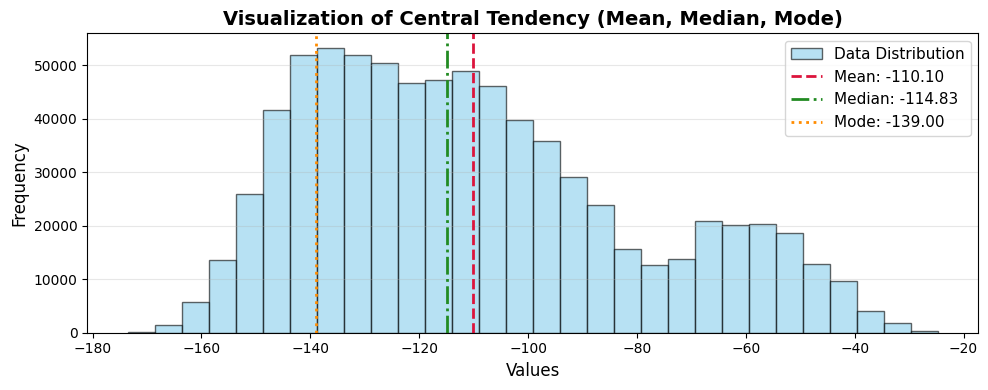

In [204]:
#distribution
plt.figure(figsize=(10, 4))

# Plot the distribution histogram
data = df_sorted
plt.hist(data, bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Data Distribution')

# Draw vertical lines for each central tendency metric
plt.axvline(str_mean, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {str_mean:.2f}')
plt.axvline(str_mediane, color='forestgreen', linestyle='-.', linewidth=2, label=f'Median: {str_mediane:.2f}')
plt.axvline(str_mode, color='darkorange', linestyle=':', linewidth=2, label=f'Mode: {str_mode:.2f}')

# Customize chart elements
plt.title('Visualization of Central Tendency (Mean, Median, Mode)', fontsize=14, fontweight='bold')
plt.xlabel('Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()

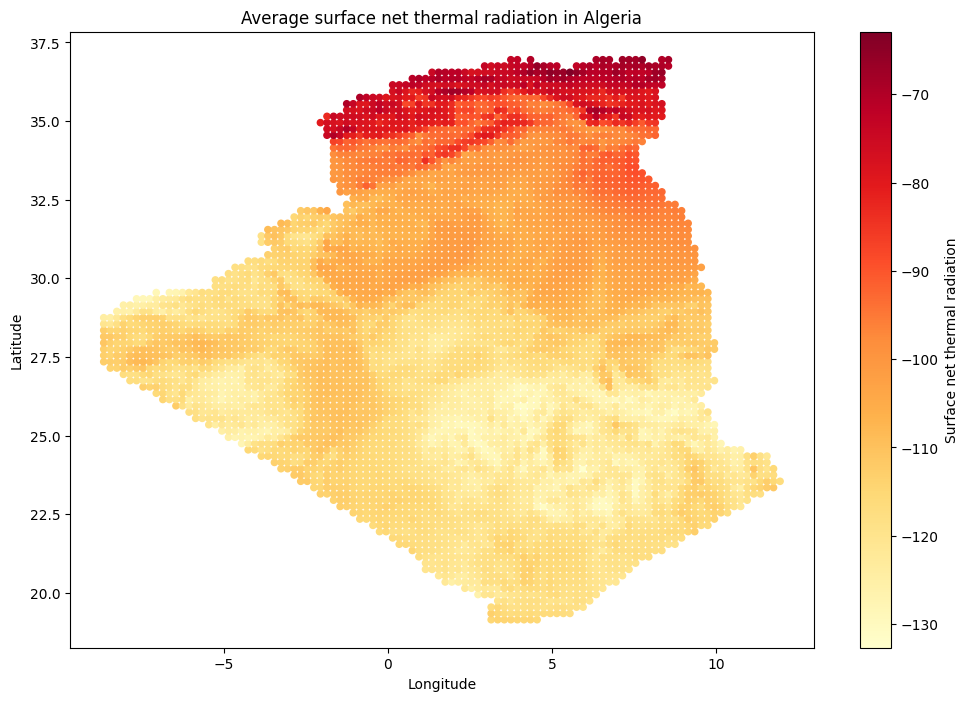

In [205]:
mean_str = df.groupby(
    ['latitude', 'longitude']
)['str'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 8))

sc = ax.scatter(
    mean_str['longitude'],
    mean_str['latitude'],
    c=mean_str['str'],
    cmap='YlOrRd',
    s=20
)

plt.colorbar(sc, ax=ax, label='Surface net thermal radiation')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Average surface net thermal radiation in Algeria')

plt.show()

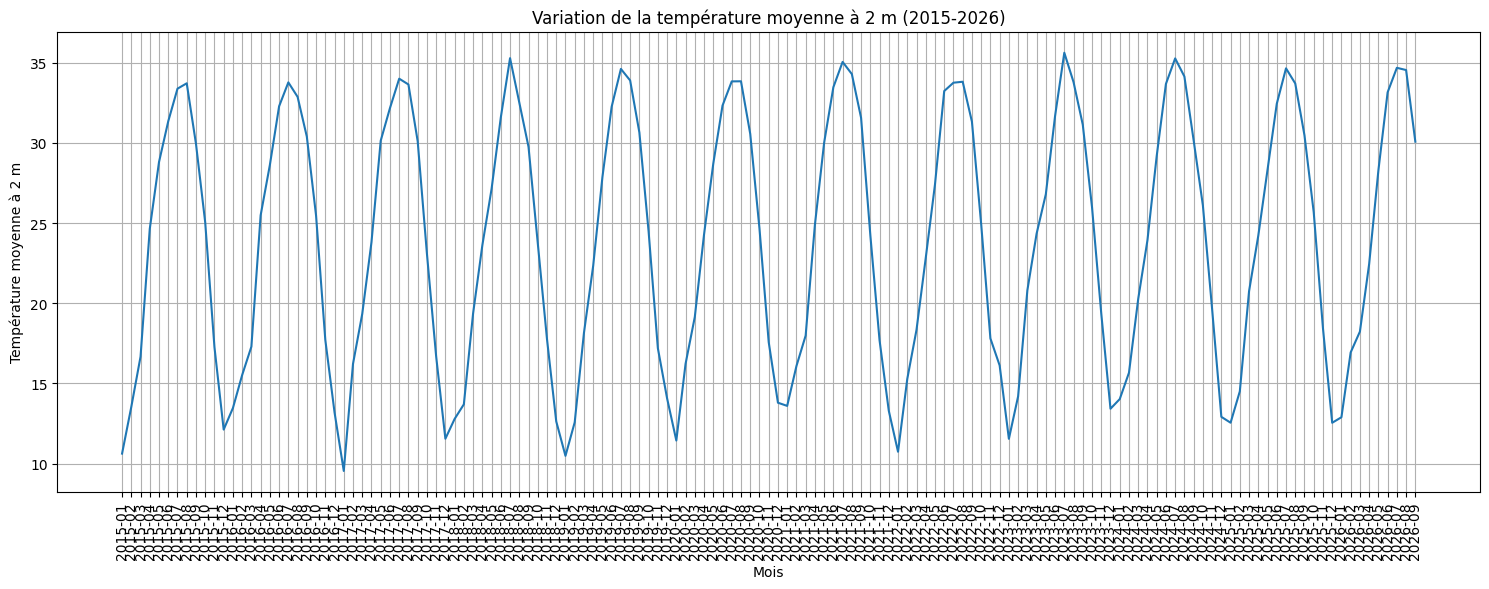

In [206]:
import pandas as pd
#variation de la temperature moyenne a 2m chaque mois entre 2015 et 2026
df['valid_time'] = pd.to_datetime(df['valid_time'])
monthly_temp = df.groupby(
    df['valid_time'].dt.to_period('M')
)['t2m'].mean()

plt.figure(figsize=(15, 6))

plt.plot(monthly_temp.index.astype(str), monthly_temp.values)

plt.title("Variation de la température moyenne à 2 m (2015-2026)")
plt.xlabel("Mois")
plt.ylabel("Température moyenne à 2 m")
plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()

## Bivariate analysis

In [207]:
def scatter_plot(year, f_1, f_2, zone, ax=None, titre=""):
    df_year = zone[pd.to_datetime(zone['valid_time']).dt.year == year]

    if ax is None:                    
        fig, ax = plt.subplots(figsize=(4, 4))
        seul = True
    else:
        seul = False

    sc = ax.scatter(df_year[f_1], df_year[f_2], s=2,
                    c=pd.to_datetime(df_year['valid_time']).dt.month, cmap="twilight")
    ax.set_xlabel(f"{f_1} ")
    ax.set_ylabel(f"{f_2} ")
    r = df_year[f_1].corr(df_year[f_2], method="spearman")
    ax.set_title(f"{titre} {year} : {f_1} vs {f_2} (r = {r:.2f})")

    if seul:
        plt.colorbar(sc, label="mois")
        plt.show()
    return sc

nord = df[(df["latitude"].between(35, 37)) & (df["longitude"].between(-1, 5))]
sud = df[(df["latitude"].between(25, 29)) & (df["longitude"].between(-2, 4))]

## 1. d2m-t2m

In [208]:
corr = df[['t2m','d2m']].corr(method='spearman', numeric_only=True)
print("global correlation : ",corr['t2m'].iloc[1])



global correlation :  0.3773030887078999


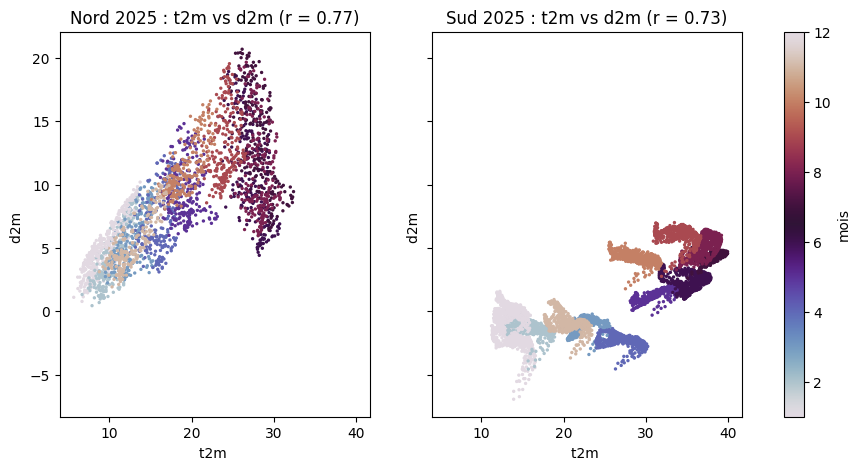

In [209]:
#scatter plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
scatter_plot(2025, 't2m', 'd2m', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 't2m', 'd2m', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interprétation

- La corrélation entre d2m et t2m dépend de la région et du mois.
- le nuage forme une bande par mois.
- Les bandes montent de l'hiver vers l'été.
- t2m et d2m augmentent donc ensemble au cours de l'année.
- d2m dans le sud et dans le nord en hiver est plus basse



## 2. t2m - ssr

In [210]:
corr = df[['t2m','ssr']].corr(method='spearman', numeric_only=True)
print("global correlation : ",corr['t2m'].iloc[1])

global correlation :  0.6125271327121009


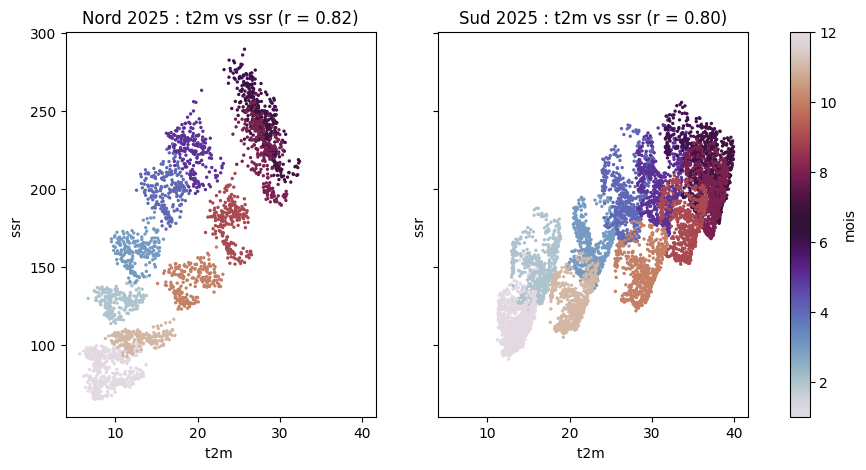

In [211]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
scatter_plot(2025, 't2m', 'ssr', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 't2m', 'ssr', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interprétation

- meme interpretation que d2m et t2m car l'augmentation du rayonnement du soleil chauffe la surface de la terre ce qui implique l'augmentation de la temperature




## 3. t2m vs str

In [212]:
corr = df[['t2m','str']].corr(method='spearman', numeric_only=True)
print("global correlation : ",corr['t2m'].iloc[1])

global correlation :  -0.6556337092691928


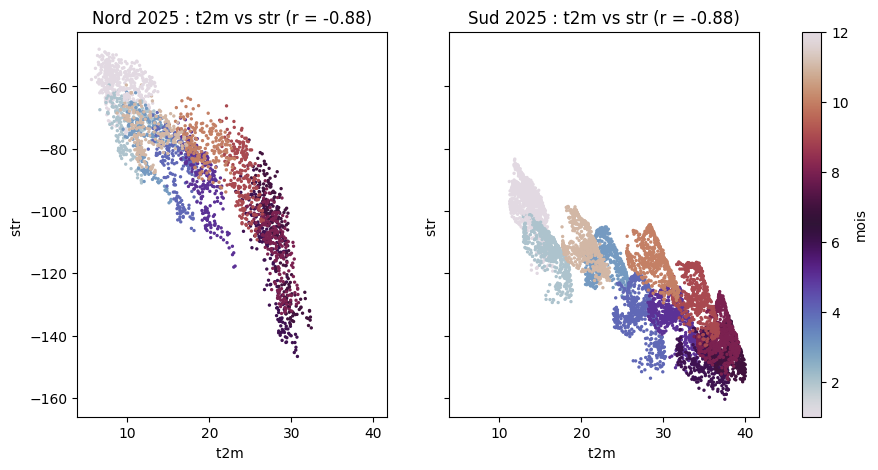

In [213]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
scatter_plot(2025, 't2m', 'str', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 't2m', 'str', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

## Interpretation
- La corrélation est négative et forte au nord (r = -0,84) comme au sud (r = -0,82).
- str est négatif : la surface perd de l'énergie par rayonnement thermique.


## 4. t2m vs slhf

In [214]:
corr = df[['t2m','slhf']].corr(method='spearman', numeric_only=True)
print("global correlation : ",corr['t2m'].iloc[1])

global correlation :  -0.16171157652609813


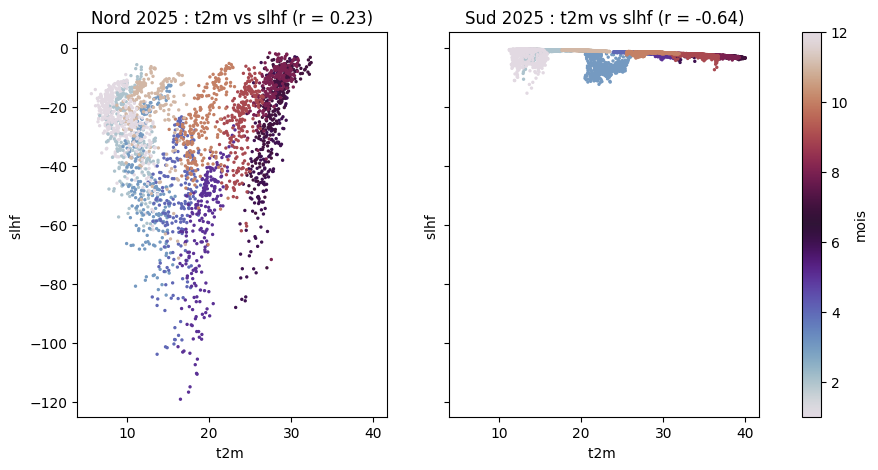

In [215]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
scatter_plot(2025, 't2m', 'slhf', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 't2m', 'slhf', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- au nord : slhf varie entre -4 et 0 mais y'a pas une correlation
- au sud : slhf est presque nulle peu importe la temperature
- dans les deux regions y'a pas de correlation

## 5. t2m vs sshf

In [216]:
corr = df[['t2m','sshf']].corr(method='spearman', numeric_only=True)
print("global correlation : ",corr['t2m'].iloc[1])

global correlation :  -0.6030265453711926


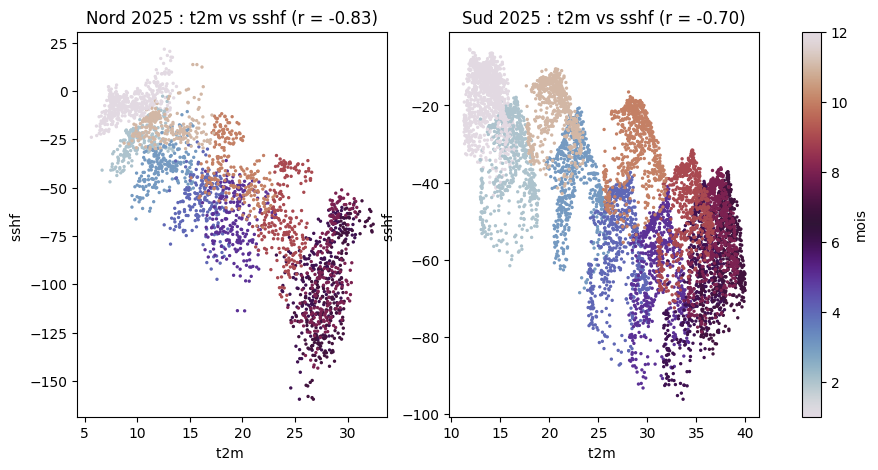

In [217]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 't2m', 'sshf', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 't2m', 'sshf', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- 

## 6. t2m vs sp

In [218]:
corr = df[['t2m','sp']].corr(method='spearman', numeric_only=True)
print("global correlation : ",corr['t2m'].iloc[1])

global correlation :  0.07088575566187186


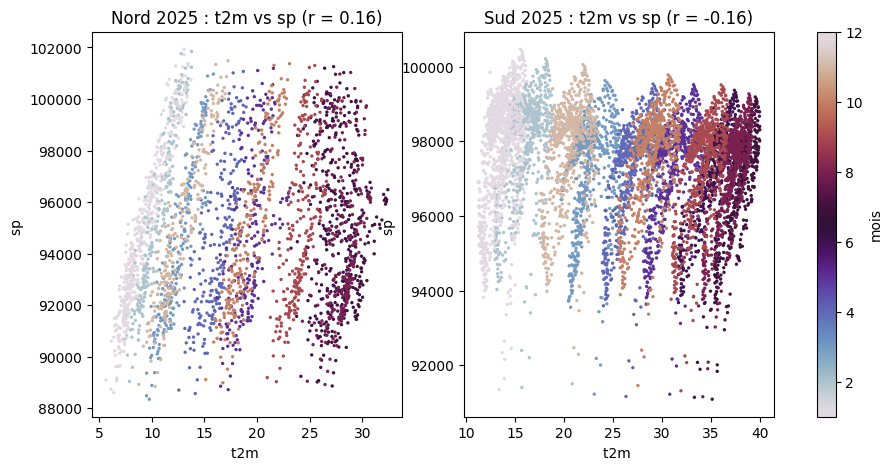

In [219]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 't2m', 'sp', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 't2m', 'sp', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- 

## 7. t2m vs tp

In [220]:
corr = df[['t2m','tp']].corr(method='pearson', numeric_only=True)
print("global correlation : ",corr['t2m'].iloc[1])

global correlation :  -0.29590180879684974


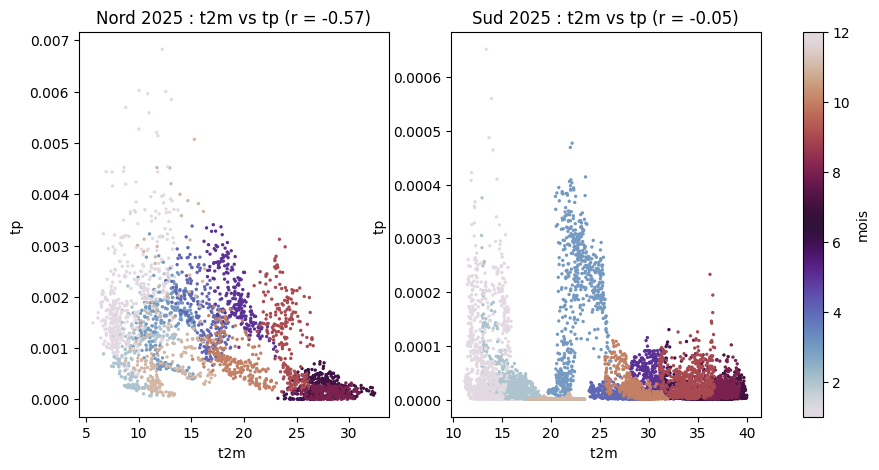

In [221]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 't2m', 'tp', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 't2m', 'tp', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- 

## 8. t2m vs u10

In [222]:
corr = df[['t2m','u10']].corr(method='pearson', numeric_only=True)
print("global correlation : ",corr['t2m'].iloc[1])

global correlation :  -0.2892844927306253


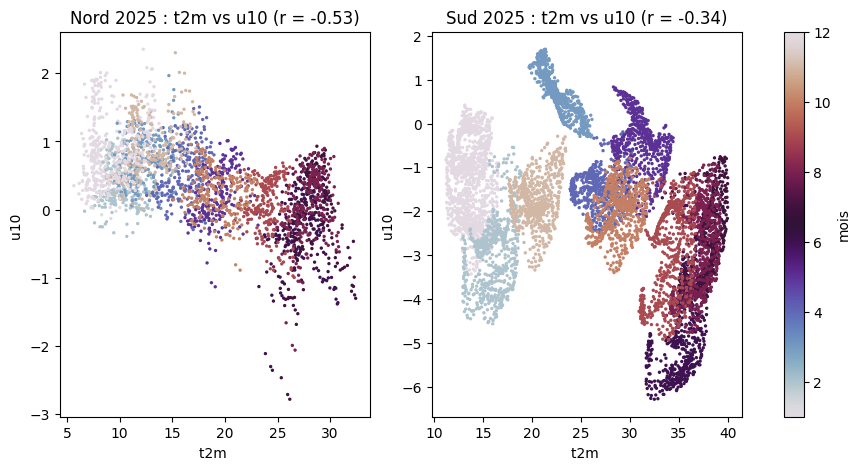

In [223]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 't2m', 'u10', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 't2m', 'u10', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- 

## 9. ssr vs sshf

In [224]:
corr = df[['ssr','sshf']].corr(method='pearson', numeric_only=True)
print("global correlation : ",corr['ssr'].iloc[1])

global correlation :  -0.9265952761138544


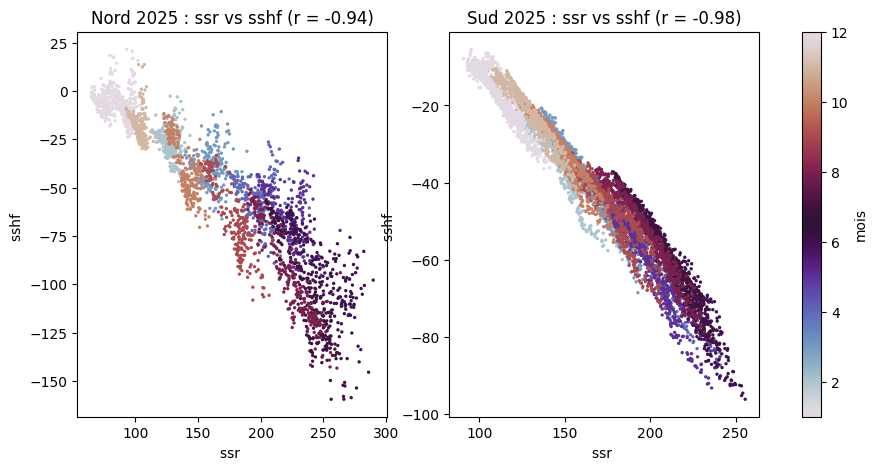

In [225]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 'ssr', 'sshf', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 'ssr', 'sshf', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- 

## 10. ssr vs slhf

In [226]:
corr = df[['ssr','slhf']].corr(method='pearson', numeric_only=True)
print("global correlation : ",corr['ssr'].iloc[1])

global correlation :  -0.1268612991999697


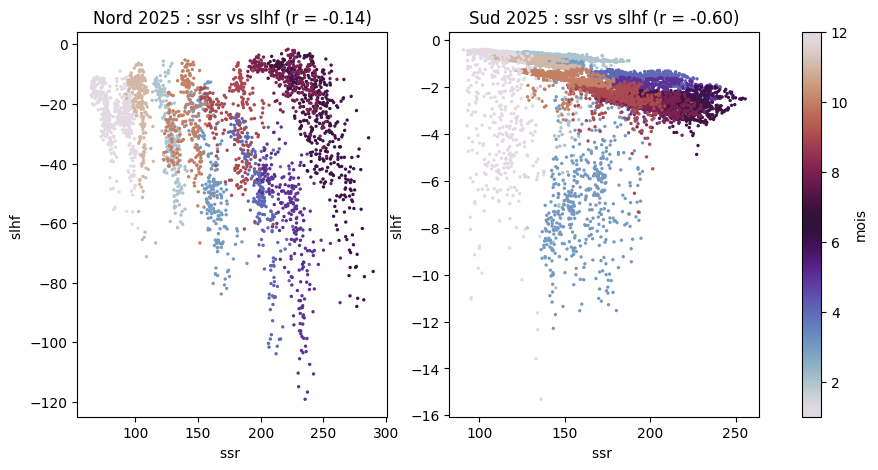

In [227]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 'ssr', 'slhf', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 'ssr', 'slhf', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- 

## 11. slhf vs e

In [228]:
corr = df[['slhf','e']].corr(method='pearson', numeric_only=True)
print("global correlation : ",corr['slhf'].iloc[1])

global correlation :  0.9999999071261121


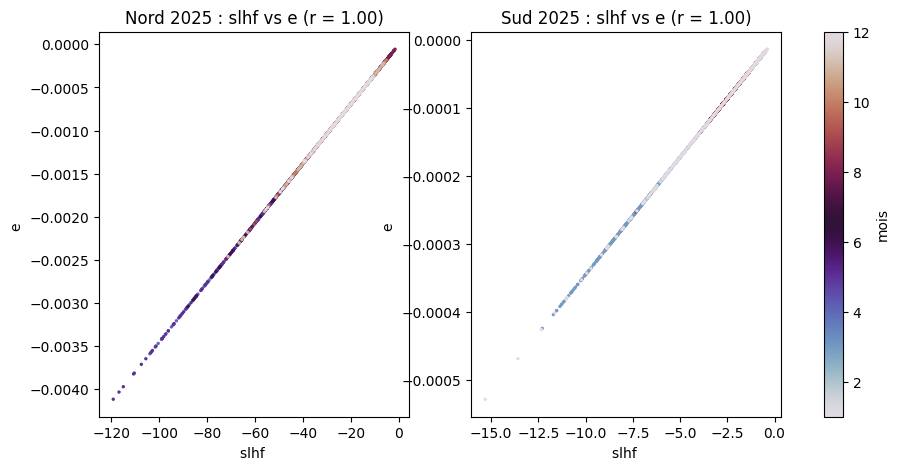

In [229]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 'slhf', 'e', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 'slhf', 'e', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- La corrélation est parfaite (r = 1,00) au nord comme au sud.
- slhf et e mesurent le même phénomène : l'évaporation (e = slhf divisé par une constante).
- Les deux variables sont redondantes.

## 12. tp vs ro

In [230]:
corr = df[['tp','ro']].corr(method='pearson', numeric_only=True)
print("global correlation : ",corr['tp'].iloc[1])

global correlation :  0.5275052455134939


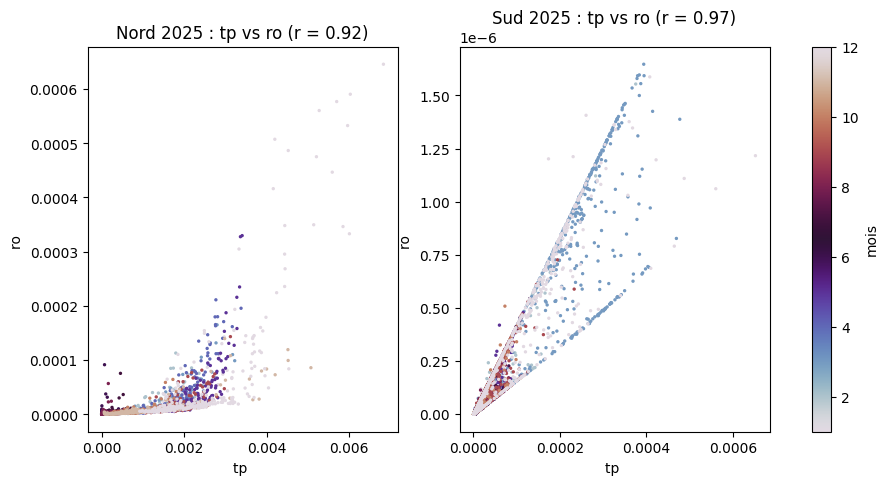

In [231]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 'tp', 'ro', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 'tp', 'ro', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- 

## 13. d2m vs tp

In [232]:
corr = df[['d2m','tp']].corr(method='pearson', numeric_only=True)
print("global correlation : ",corr['d2m'].iloc[1])

global correlation :  0.29685542960538924


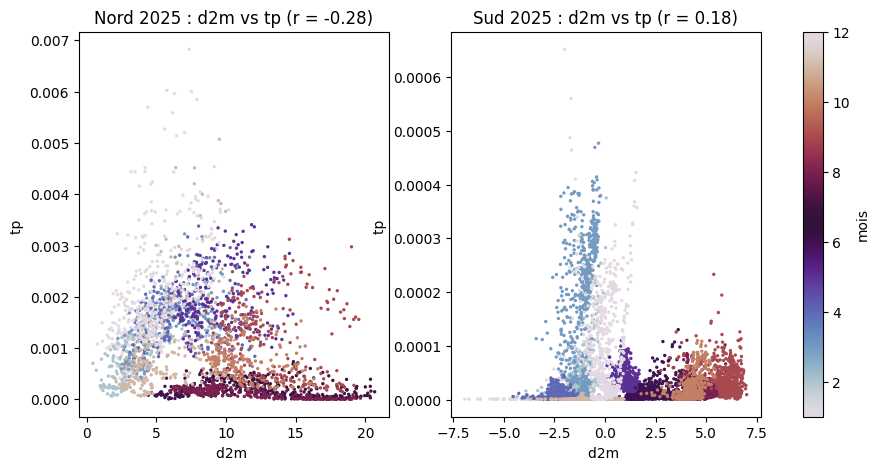

In [233]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 'd2m', 'tp', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 'd2m', 'tp', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- 

## 14. d2m vs str

In [234]:
corr = df[['d2m','str']].corr(method='pearson', numeric_only=True)
print("global correlation : ",corr['d2m'].iloc[1])

global correlation :  0.11561600399005627


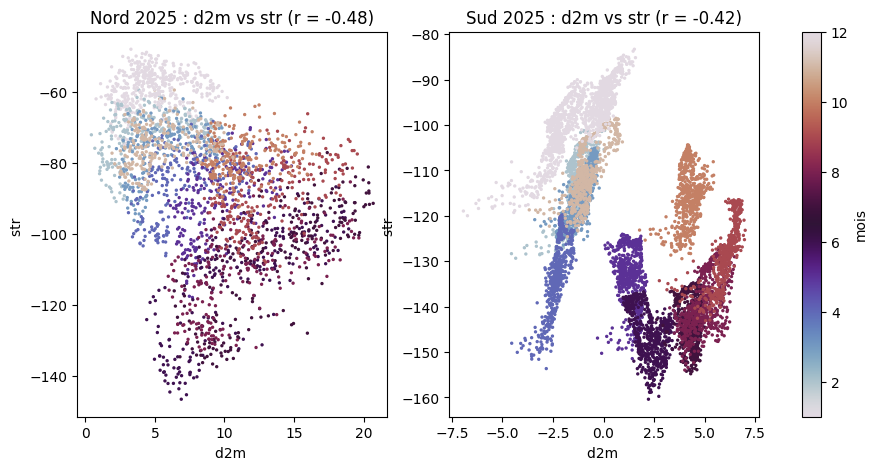

In [235]:
#scatter_plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=False, sharey=False)
scatter_plot(2025, 'd2m', 'str', nord, ax=axes[0], titre="Nord")
sc = scatter_plot(2025, 'd2m', 'str', sud, ax=axes[1], titre="Sud")

fig.colorbar(sc, ax=axes, label="mois")
plt.show()

### Interpretation
- 

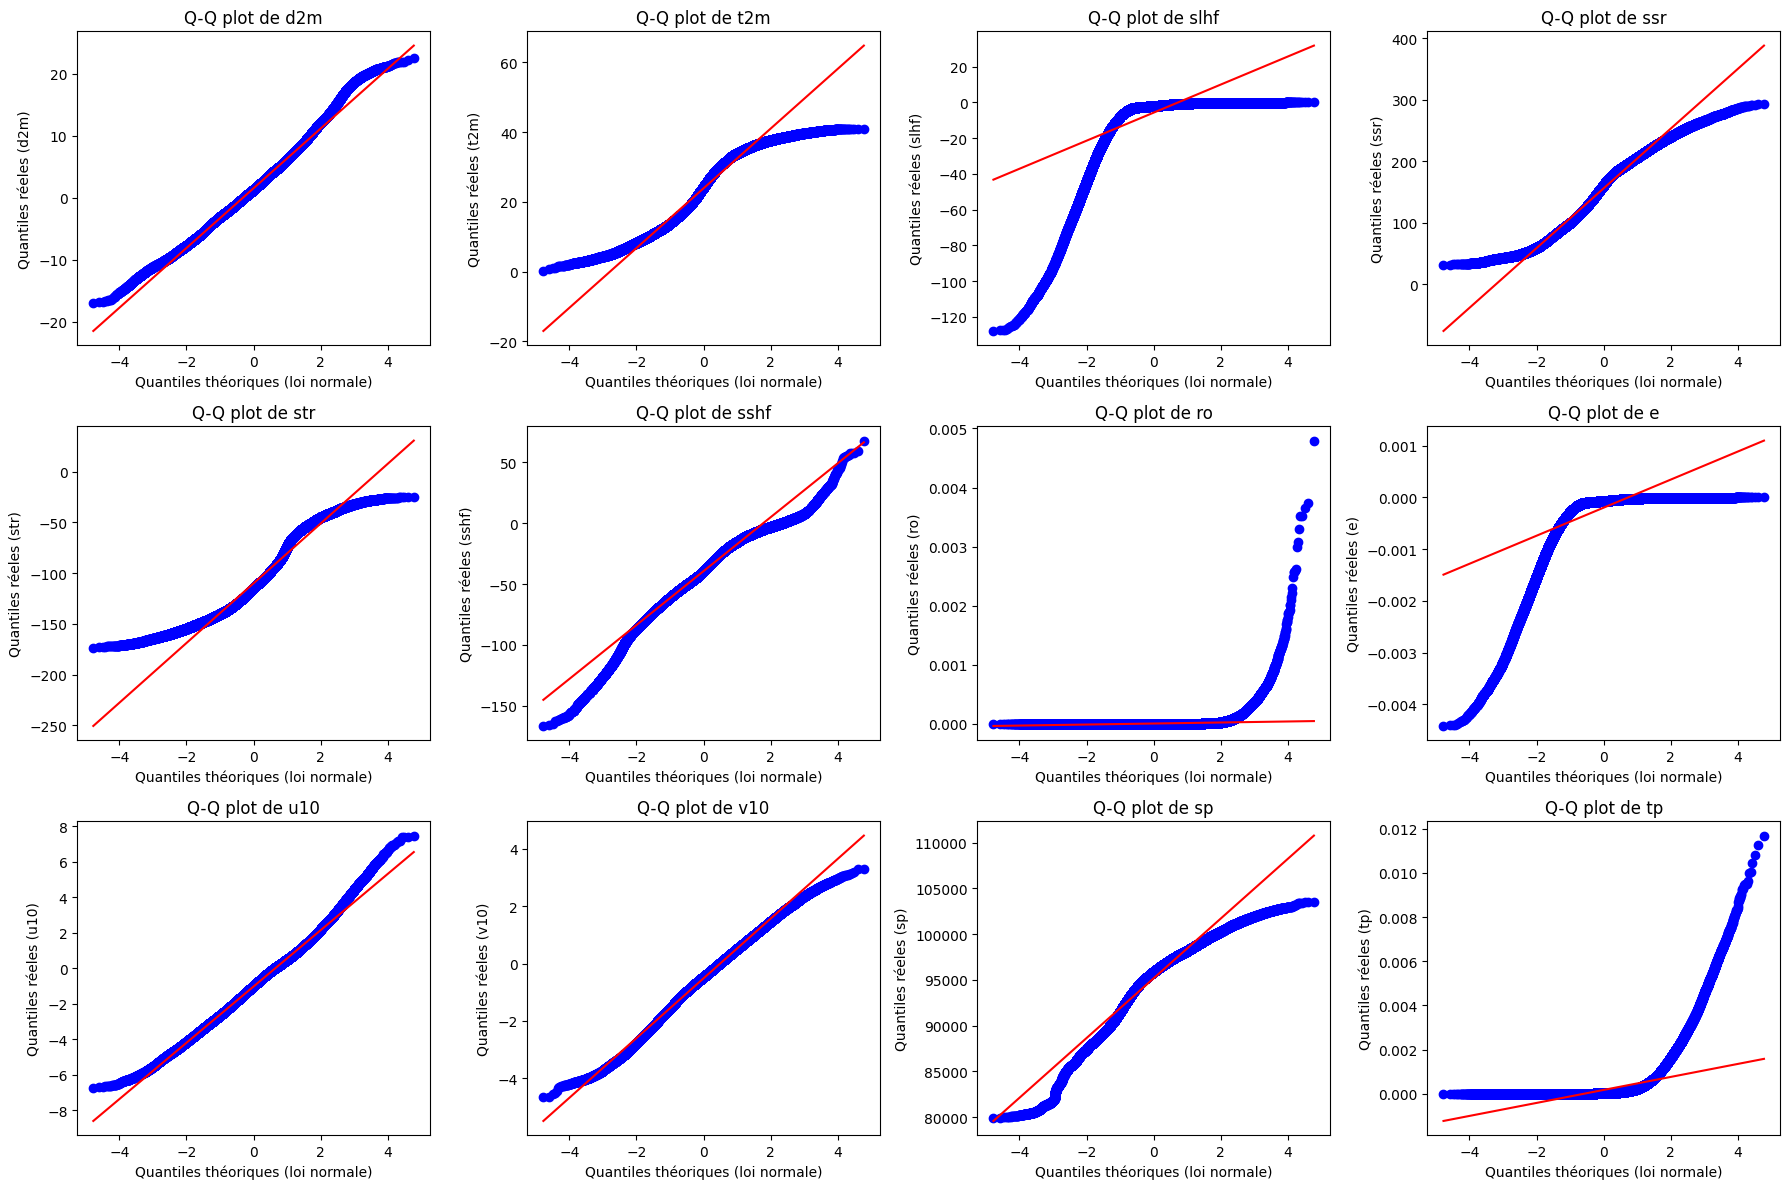

In [240]:
from scipy import stats

cols = ['d2m', 't2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for ax, c in zip(axes.ravel(), cols):
    s = df[c]  
    stats.probplot(s, dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot de {c}")
    ax.set_xlabel("Quantiles théoriques (loi normale)")
    ax.set_ylabel(f"Quantiles réeles ({c})")

plt.tight_layout()
plt.show()